Ce notebook fait suite au premier notebook de préparation et nettoyage des données, qui produit en sortie le fichier `donnees_final.csv` utilisé ici comme point de départ.

 L'objectif est de réaliser une ACP et un clustering (CAH puis K-means), pour identifier des groupes de pays et recommander des marchés cibles pour l'export de "La poule qui chante".

In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import fcluster
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt

In [68]:
drive = True
if drive:
  from google.colab import drive
  drive.mount("/content/drive")

  df_final = pd.read_csv("/content/drive/MyDrive/Nadia Openclassrooms/Projet 11/Data/donnees_final.csv", encoding='utf-8')
  print("Les fichiers ont été importés via le Drive")
else:
  df_final = pd.read_csv("donnees_final.csv", encoding='utf-8')
  print("Les fichiers ont été importés")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Les fichiers ont été importés via le Drive


# 1 - Analyse exploratoire


Aperçu des données, statistiques descriptives et distributions avant tout traitement.

### 1.1 Aperçu des données

In [69]:
df_final.head()

,Zone,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique,distance_fr_km
0,Afghanistan,1.53,0.0,29.0,28.0,36296.113,2335.795862,24.835282,21.244270,5595.496748
1,Afrique du Sud,35.69,63.0,514.0,1667.0,57009.756,13738.438585,63.331108,59.355008,8649.467089
2,Albanie,16.36,0.0,38.0,13.0,2884.169,14110.672057,55.980276,68.692869,1604.449323
3,Algérie,6.38,0.0,2.0,275.0,41389.189,13493.560749,71.322791,50.016967,1346.107790
4,Allemagne,19.47,646.0,842.0,1514.0,82658.409,54142.741486,80.984254,77.889508,879.241272


In [70]:
df_final.describe()

,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique,distance_fr_km
count,163.000000,163.000000,163.000000,163.000000,1.630000e+02,163.000000,163.000000,163.000000,163.000000
mean,19.725706,105.361963,83.987730,738.104294,4.443324e+04,19804.135194,58.259057,64.586487,5807.160911
std,15.697891,468.002728,178.268558,2538.226013,1.570783e+05,18994.460582,21.245308,14.319939,3820.339521
min,0.130000,0.000000,0.000000,0.000000,5.204500e+01,883.810735,15.963428,21.244270,1.780359
25%,6.185000,0.000000,3.000000,12.000000,2.902508e+03,5001.890559,40.698045,55.171578,2365.602954
50%,17.030000,0.000000,16.000000,69.000000,9.729823e+03,13610.472314,60.145888,65.410950,5414.371374
75%,28.585000,14.000000,78.500000,376.500000,3.170204e+04,28582.968637,74.318332,77.206045,8575.256208
max,72.310000,4223.000000,1069.000000,21914.000000,1.421022e+06,114985.842236,100.000000,91.388422,18980.732071


### 1.2 Distributions des variables

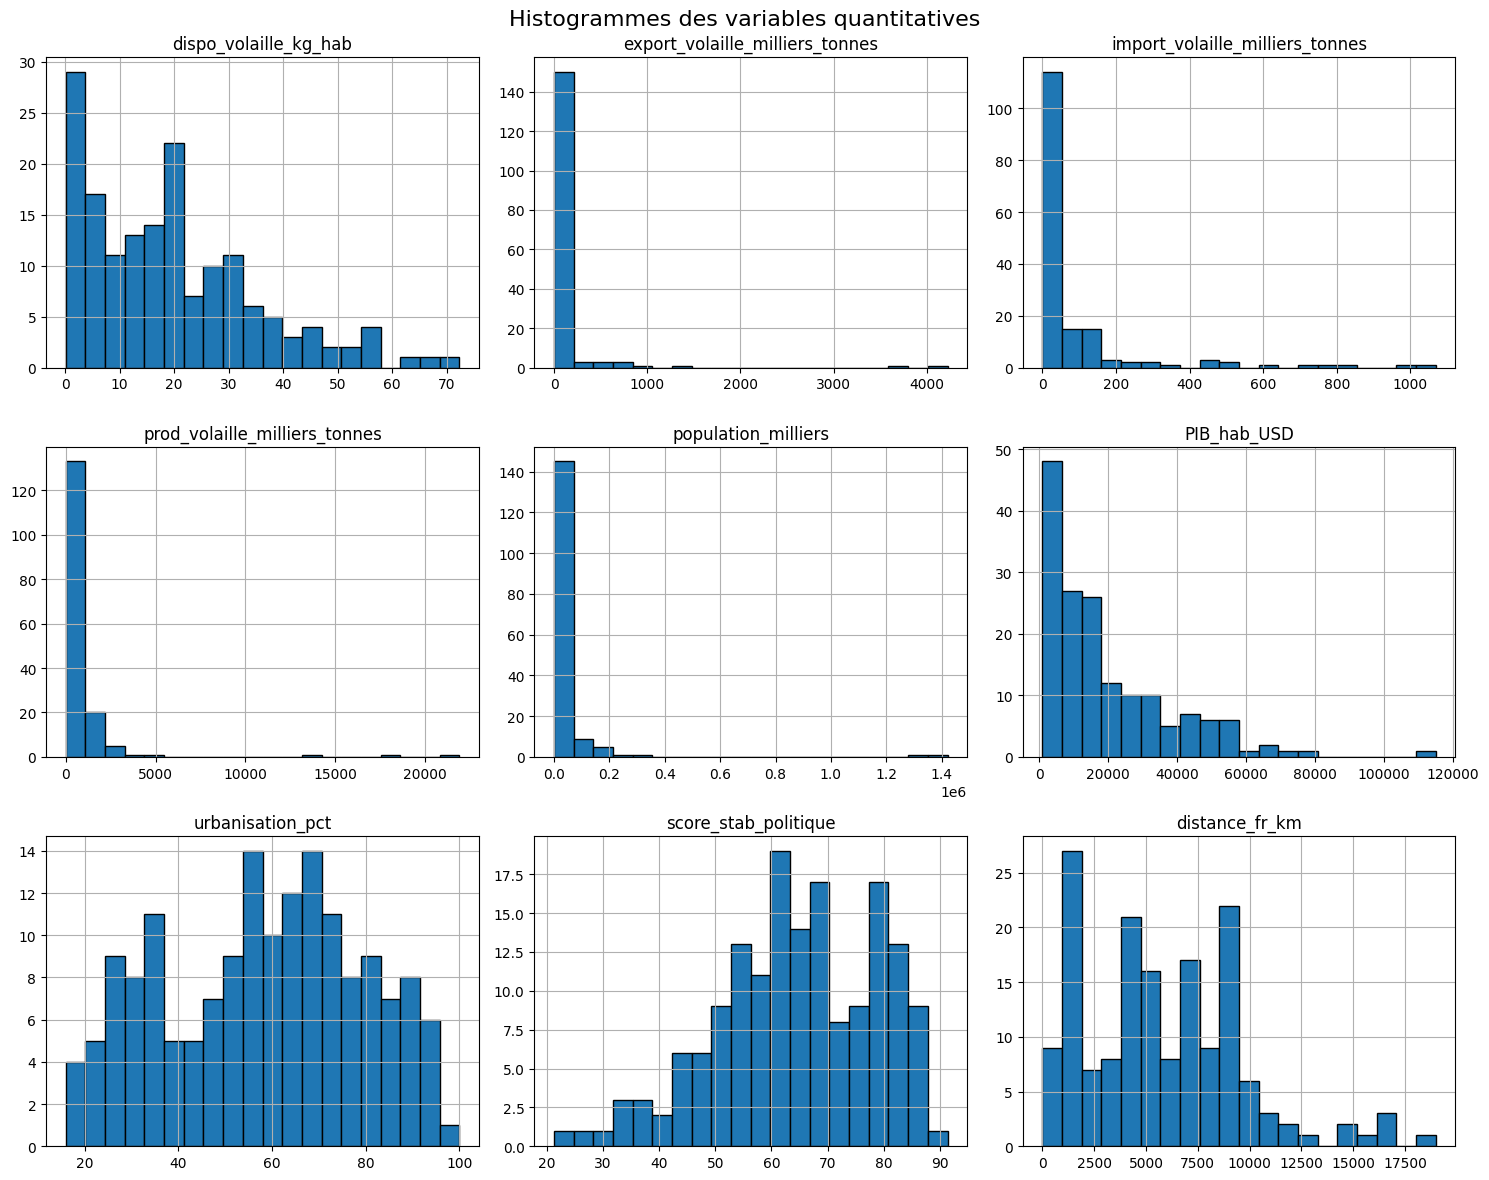

In [71]:
#Graphique
df_final.drop(columns=['Zone']).hist(figsize=(15, 12), bins=20, edgecolor='black')
plt.suptitle("Histogrammes des variables quantitatives", fontsize=16)
plt.tight_layout()
plt.show()

Les histogrammes montrent que la population, l’export, la production et l’import ont des distributions très asymétriques, la plupart des pays présentent des valeurs faibles, tandis que quelques géants tirent l’échelle vers le haut.

### 1.3 Valeurs extrêmes

In [72]:
variables = df_final.drop(columns=['Zone']).columns

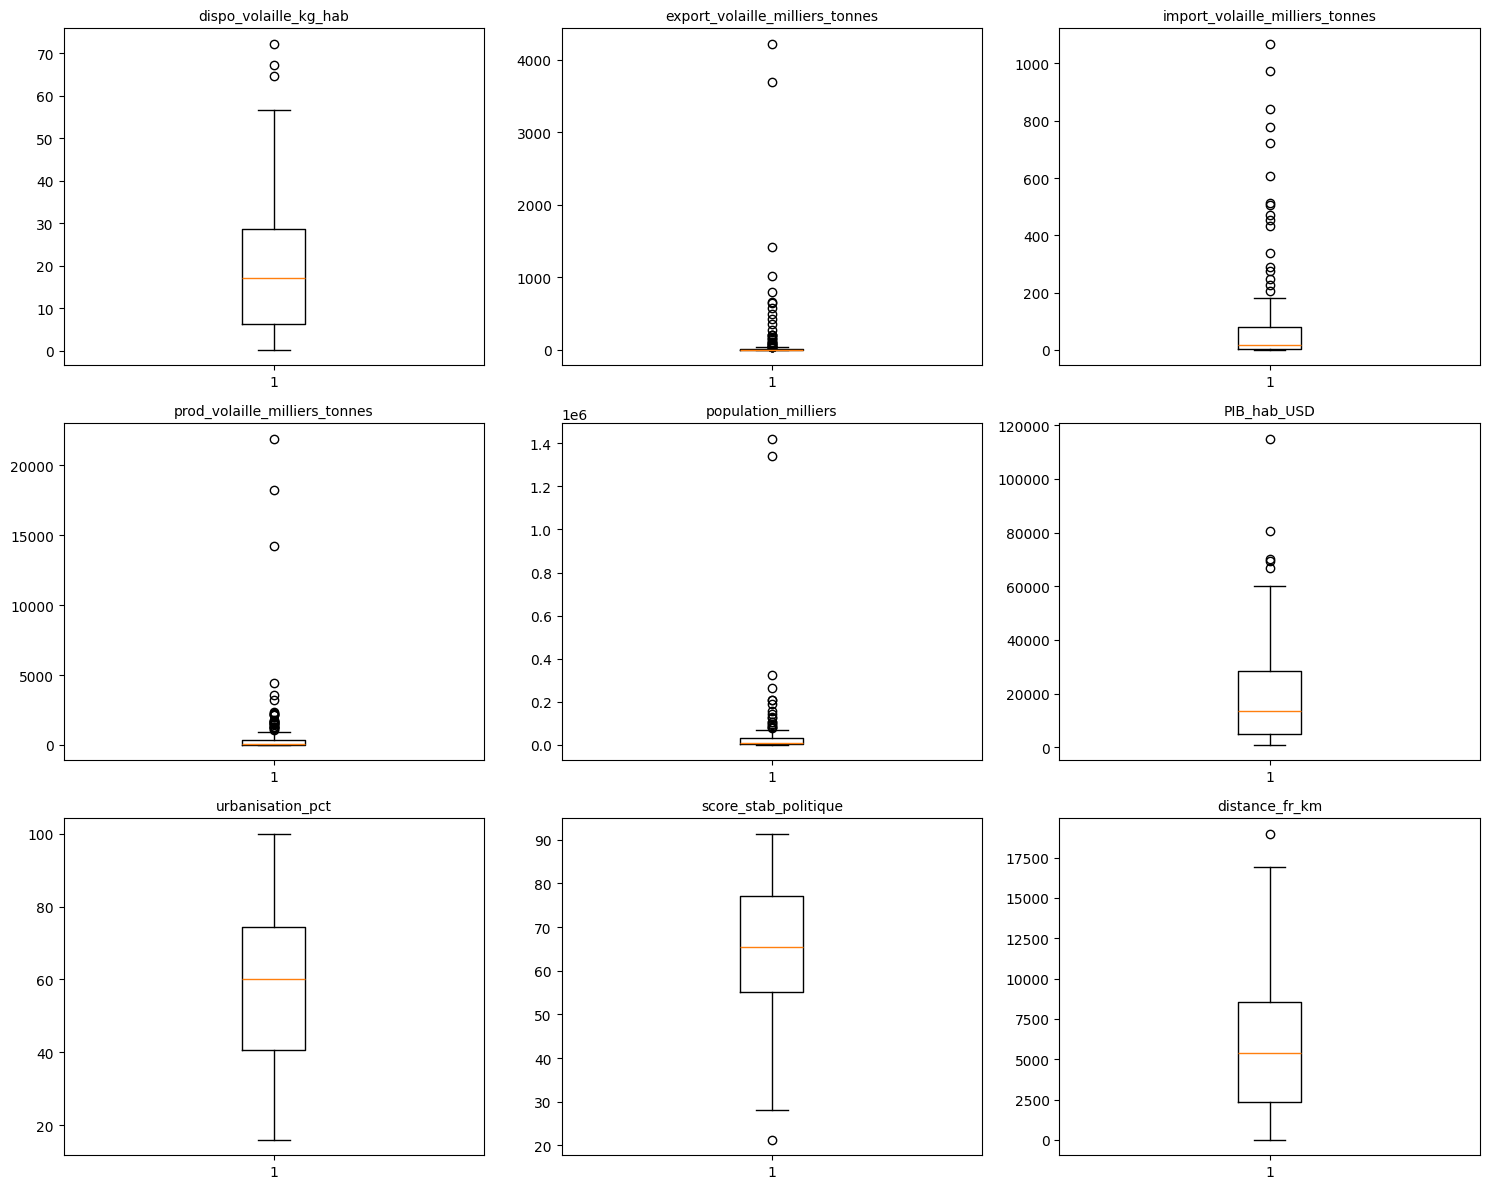

In [73]:
#Graphique
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, var in enumerate(variables):
    axes[i].boxplot(df_final[var])
    axes[i].set_title(var, fontsize=10)

plt.tight_layout()
plt.show()

Les boxplots confirment la présence de valeurs extrêmes sur plusieurs variables, notamment celles liées à la taille des pays, à l'import, à l'export et à la production de volaille.

### 1.4 Matrice de corrélation

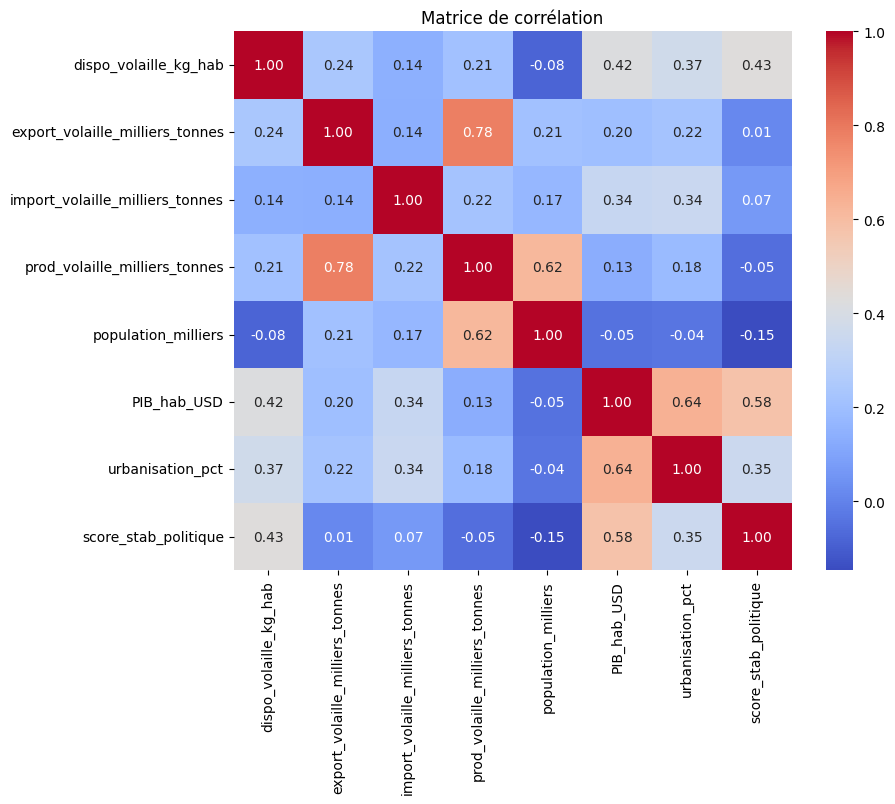

In [74]:
#Matrice
plt.figure(figsize=(9, 7))
sns.heatmap(df_final.drop(columns=['Zone', 'distance_fr_km']).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

Aucune corrélation ne dépasse 0.78, les variables ne sont pas redondantes entre elles, on peut donc toutes les conserver pour l'ACP.

# 2 - Standardisation des variables

La standardisation met toutes les variables à la même échelle, pour qu'aucune ne domine les autres dans les calculs à cause de son unité ou de sa taille de valeurs.

La variable **distance_fr_km** est exclue de cette standardisation, elle sera ajoutée seulement à la fin comme variable supplémentaire, une fois les recommandations de pays établies.

### 2.1 Z-score

In [75]:
col_zones = df_final['Zone']
col_distance = df_final['distance_fr_km']

X = df_final.drop(columns=['Zone', 'distance_fr_km'])

#z-score
X_scaled = (X - X.mean()) / X.std()
X_scaled.head()

,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique
0,-1.159118,-0.225131,-0.308454,-0.279764,-0.051803,-0.919654,-1.573231,-3.026704
1,1.016971,-0.090516,2.412160,0.365963,0.080065,-0.319340,0.238737,-0.365328
2,-0.214405,-0.225131,-0.257969,-0.285674,-0.264512,-0.299743,-0.107260,0.286760
3,-0.850159,-0.225131,-0.459911,-0.182452,-0.019379,-0.332232,0.614900,-1.017429
4,-0.016289,1.155203,4.252081,0.305684,0.243351,1.807822,1.069657,0.928986


### 2.2 Vérification

In [76]:
idx = ["mean", "std"]
pd.DataFrame(X_scaled).describe().round(2).loc[idx, :]

,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique
mean,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Après transformation, chaque variable présente bien une moyenne proche de 0 et un écart-type égal à 1, confirmant que la standardisation a été appliquée correctement sur l'ensemble des 8 variables retenues.

# 3 - ACP

L'ACP résume les 8 variables standardisées en quelques axes, pour visualiser les pays sur un graphique en 2D tout en gardant le maximum d'information.

### 3.1 Variance expliquée

La variance expliquée indique la part d'information que capture chaque axe. On calcule aussi son cumul, pour savoir combien d'axes garder afin de résumer l'essentiel des différences entre pays.

In [77]:
pca = PCA()
composantes = pca.fit_transform(X_scaled)
variance_ratio = pca.explained_variance_ratio_

print(variance_ratio)
print(np.cumsum(variance_ratio))

[0.34904714 0.2514291  0.124373   0.09151656 0.07563982 0.06088414
 0.03554709 0.01156315]
[0.34904714 0.60047624 0.72484925 0.8163658  0.89200562 0.95288976
 0.98843685 1.        ]


Les deux premiers axes concentrent déjà 60% de l'information:

*   **F1**: 34.9%
*   **F2**: 25.1%

On peut donc se limiter à quelques axes pour résumer l'essentiel des différences entre pays.

### 3.2 Poids des variables sur les axes

In [78]:
pcs = pca.components_
pcs

array([[ 0.38180927,  0.34638176,  0.29387264,  0.34298932,  0.12094936,
         0.46698887,  0.44032918,  0.32193389],
       [-0.17644475,  0.39226969,  0.05269021,  0.5424171 ,  0.51174576,
        -0.26717677, -0.18782143, -0.38659428],
       [-0.3693016 , -0.36226448,  0.74386696, -0.16152992,  0.21842491,
         0.11530215,  0.21129478, -0.21748862],
       [ 0.0060592 , -0.4257076 , -0.20994445,  0.0207204 ,  0.68391239,
         0.10051275, -0.20853224,  0.50289726],
       [ 0.73990065, -0.16532992,  0.41617388, -0.02408695,  0.00293478,
        -0.30941158, -0.38703221, -0.076773  ],
       [ 0.35063216, -0.31748612, -0.35682591, -0.03474729,  0.24152755,
        -0.07702552,  0.58519506, -0.49092343],
       [ 0.10010152, -0.0278782 , -0.11211119, -0.06047526,  0.03291257,
         0.76352193, -0.43501716, -0.44686396],
       [-0.07907178, -0.53364131, -0.01880289,  0.74577205, -0.38550554,
         0.05006371, -0.03485731,  0.01044904]])

In [79]:
pcs = pd.DataFrame(pcs)
pcs.columns = X_scaled.columns
x_list = list(range(1, 9))
pcs.index = [f"F{i}" for i in x_list]
pcs.round(2)

,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique
F1,0.38,0.35,0.29,0.34,0.12,0.47,0.44,0.32
F2,-0.18,0.39,0.05,0.54,0.51,-0.27,-0.19,-0.39
F3,-0.37,-0.36,0.74,-0.16,0.22,0.12,0.21,-0.22
F4,0.01,-0.43,-0.21,0.02,0.68,0.10,-0.21,0.50
F5,0.74,-0.17,0.42,-0.02,0.00,-0.31,-0.39,-0.08
F6,0.35,-0.32,-0.36,-0.03,0.24,-0.08,0.59,-0.49
F7,0.10,-0.03,-0.11,-0.06,0.03,0.76,-0.44,-0.45
F8,-0.08,-0.53,-0.02,0.75,-0.39,0.05,-0.03,0.01


Chaque axe est une combinaison des 8 variables, mais avec un poids différent pour chacune. Ce tableau donne, pour chaque variable, son poids sur chaque axe. Plus il est élevé, plus la variable contribue à cet axe.

- **F1** : PIB_hab_USD (0.47) et urbanisation_pct (0.44) ont les poids les plus élevés, cet axe reflète surtout le niveau de développement du pays.
- **F2** : prod_volaille (0.54) et population_milliers (0.51) dominent, opposés à score_stab_politique (-0.39), cet axe distingue les gros producteurs des pays plutôt riches et stables.
- **F3** : import_volaille (0.74) domine largement, cet axe reflète surtout la capacité d'importation du pays.

### 3.3 Éboulis des valeurs propres

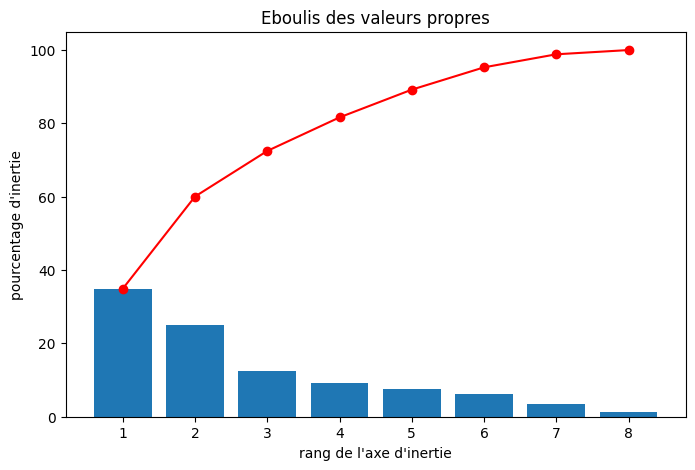

In [80]:
#graphique
plt.figure(figsize=(8,5))
plt.bar(range(1, 9), variance_ratio * 100)
plt.plot(range(1, 9), variance_ratio.cumsum() * 100, color='red', marker='o')
plt.xlabel("rang de l'axe d'inertie")
plt.ylabel("pourcentage d'inertie")
plt.title("Eboulis des valeurs propres")
plt.xticks(range(1, 9))
plt.show()

L'éboulis affiche visuellement la variance de chaque axe:

Le coude après le 2ᵉ axe confirme que F1 et F2 concentrent l'essentiel de l'information, les axes suivants n'apportent presque rien de plus.

### 3.4 Cercle des corrélations

In [81]:
#Fonction graphique cercle des corrélations
def correlation_graph(pca, x_y, features):
    x,y=x_y
    fig, ax = plt.subplots(figsize=(8, 7))

    for i in range(0, pca.components_.shape[1]):
        ax.arrow(0,0,
                pca.components_[x, i],
                pca.components_[y, i],
                head_width=0.07,
                head_length=0.07,
                width=0.02, )

        plt.text(pca.components_[x, i] + 0.05,
                pca.components_[y, i] + 0.05,
                features[i])

    plt.plot([-1, 1], [0, 0], color='grey', ls='--')
    plt.plot([0, 0], [-1, 1], color='grey', ls='--')
    plt.xlabel('F{} ({}%)'.format(x+1, round(100*pca.explained_variance_ratio_[x],1)))
    plt.ylabel('F{} ({}%)'.format(y+1, round(100*pca.explained_variance_ratio_[y],1)))
    plt.title("Cercle des corrélations (F{} et F{})".format(x+1, y+1))
    an = np.linspace(0, 2 * np.pi, 100)
    plt.plot(np.cos(an), np.sin(an))
    plt.axis('equal')
    plt.show(block=False)

In [82]:
pca = PCA(n_components=4)
composantes = pca.fit_transform(X_scaled)

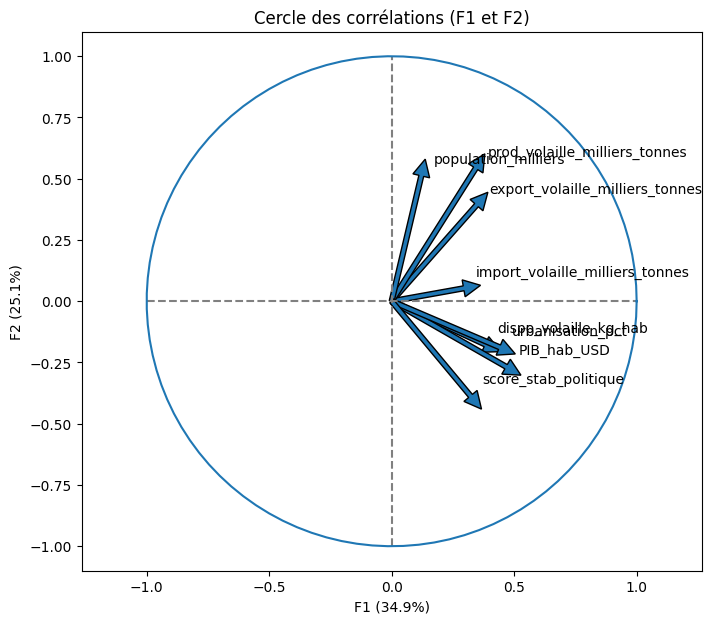

In [83]:
#Cercle F1-F2
correlation_graph(pca, [0, 1], X_scaled.columns)

Ce graphique montre comment les 8 variables se positionnent sur F1 et F2, sous forme de flèches.

Toutes les flèches pointent vers la droite, F1 résume le niveau de développement global d'un pays.

Sur l'axe vertical, F2 sépare les pays producteurs/exportateurs de volaille des pays plutôt riches et stables.

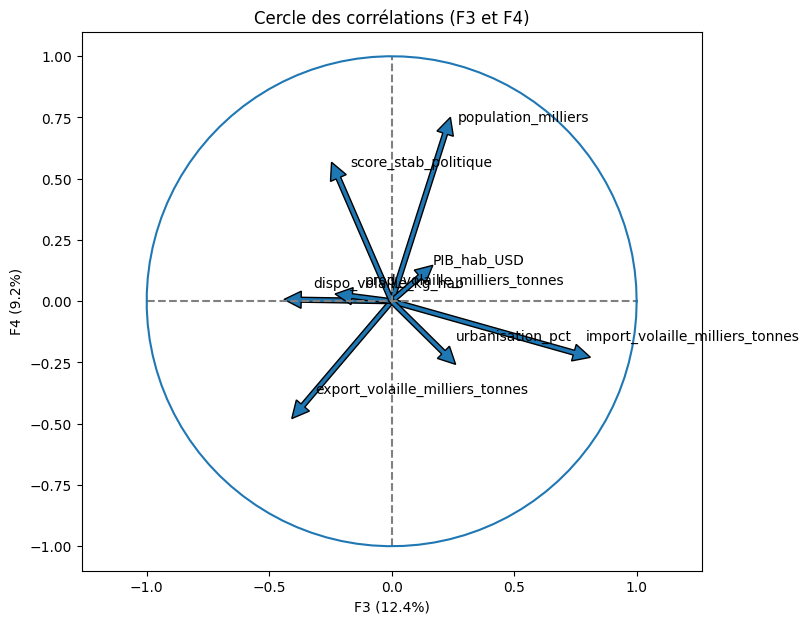

In [84]:
#Cercle F3-F4
correlation_graph(pca, [2, 3], X_scaled.columns)

Les flèches sont globalement plus courtes que sur le cercle F1-F2, ces variables sont moins bien représentées ici. F3 oppose les pays importateurs aux pays exportateurs, tandis que F4 est surtout lié à la population.

### 3.5 Projection des individus

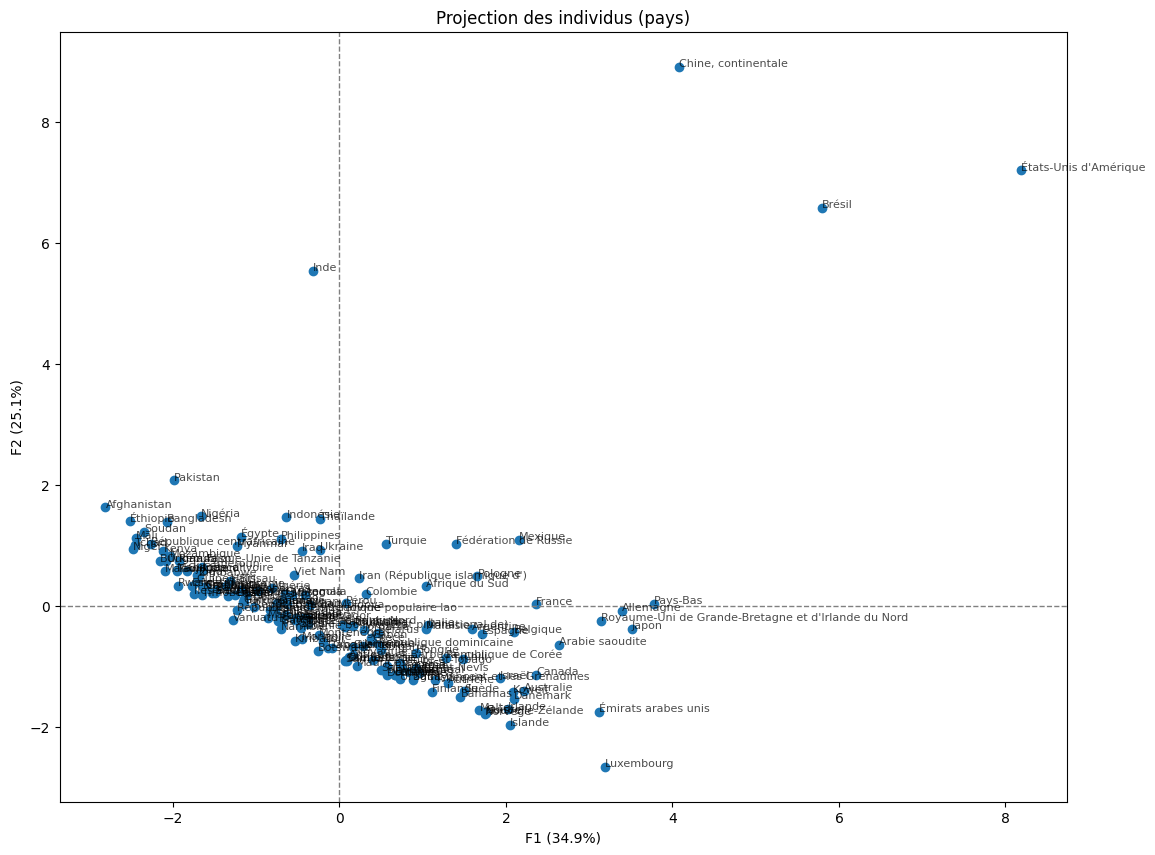

In [85]:
#Graphique
fig, ax = plt.subplots(figsize=(13, 10))
ax.scatter(composantes[:, 0], composantes[:, 1])

for i, zone in enumerate(col_zones):
    ax.annotate(zone, (composantes[i, 0], composantes[i, 1]), fontsize=8, alpha=0.7)

ax.axhline(0, color='grey', lw=1, ls='--')
ax.axvline(0, color='grey', lw=1, ls='--')
ax.set_xlabel(f"F1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"F2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Projection des individus (pays)")
plt.show()

Ce graphique projette chaque pays sur F1 et F2, à partir de ses 8 variables standardisées.
Quatre pays se détachent du reste du nuage: la Chine, l'Inde, les États-Unis et le Brésil. Leur population et leur production de volaille sont bien plus élevées que les autres pays.

# 4 - CAH (Classification Ascendante Hiérarchique)

La CAH (Classification Ascendante Hiérarchique) est une méthode de clustering qui regroupe progressivement les pays les plus semblables entre eux, jusqu'à former un arbre complet.

### 4.1 Dendrogramme

In [86]:
#Calcul de la CAH avec la méthode de Ward
Z = linkage(X_scaled, method='ward')

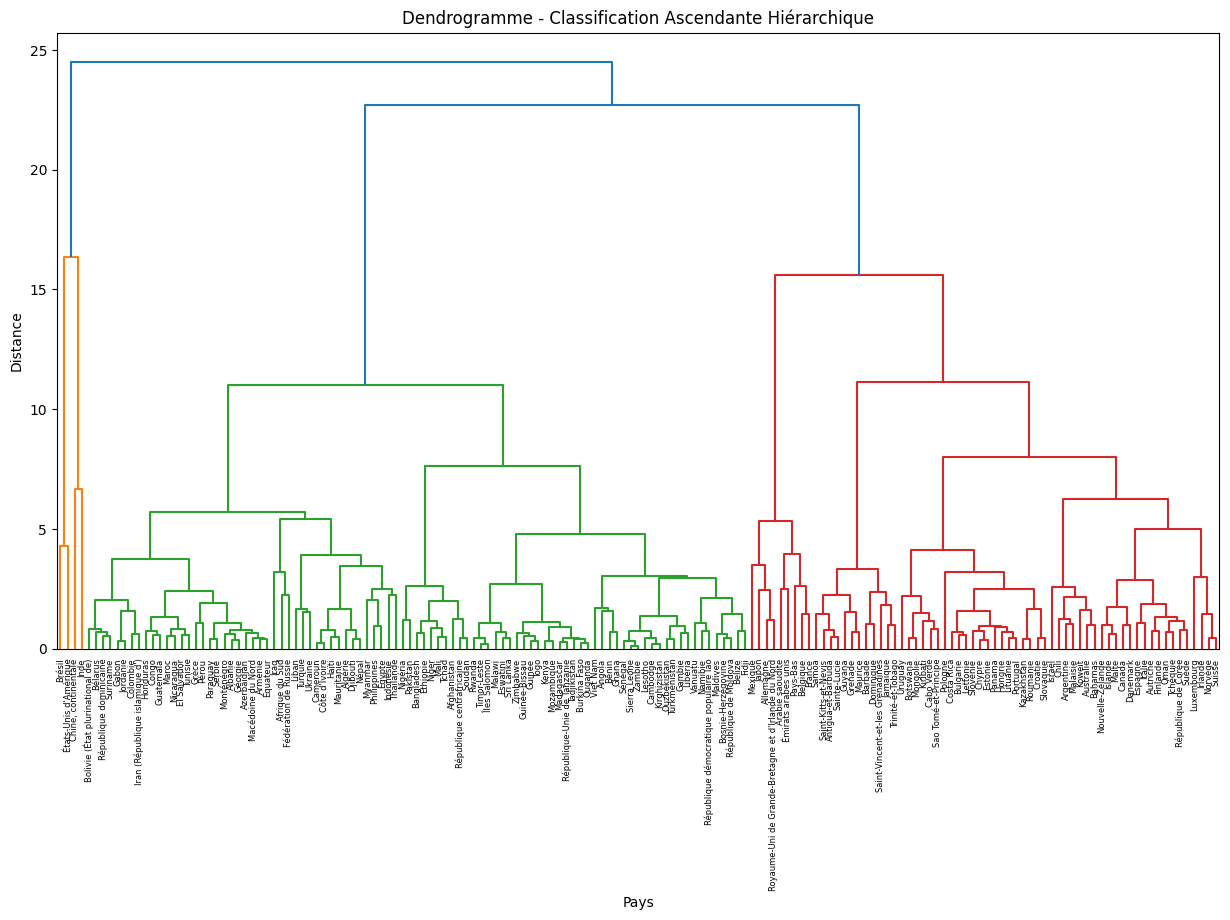

In [87]:
#Dendrogramme
plt.figure(figsize=(15, 8))
dendrogram(Z, labels=col_zones.values, leaf_rotation=90, leaf_font_size=6)
plt.title("Dendrogramme - Classification Ascendante Hiérarchique")
plt.xlabel("Pays")
plt.ylabel("Distance")
plt.show()

Le dendrogramme construit l'arbre de la CAH sur les 163 pays. On le coupe ensuite à une certaine hauteur pour décider combien de groupes garder. On remarque un grand vide entre les hauteurs 11 et 15.5, qui sépare naturellement les pays en 2 grandes familles. On voit également en orange les pays séparés très tôt du reste de l'arbre, ce qui confirme la présence de pays très atypiques.

In [88]:
#Découpe l'arbre pour obtenir 6 groupes, à titre exploratoire.
clusters_cah = fcluster(Z, t=6, criterion='maxclust')

#On ajoute le résultat à un tableau avec le nom des pays
resultats_cah = pd.DataFrame({'Zone': col_zones, 'cluster_cah': clusters_cah})
resultats_cah['cluster_cah'].value_counts()

,count
cluster_cah,
3,93
6,45
5,12
4,9
1,2
2,2


In [89]:
resultats_cah[resultats_cah['cluster_cah'].isin([1, 2])]

,Zone,cluster_cah
21,Brésil,1
31,"Chine, continentale",2
62,Inde,2
160,États-Unis d'Amérique,1


In [90]:
detail_pays_ex = resultats_cah[resultats_cah['cluster_cah'].isin([1, 2])]['Zone'].tolist()
df_final[df_final['Zone'].isin(detail_pays_ex)][['Zone', 'population_milliers', 'export_volaille_milliers_tonnes', 'prod_volaille_milliers_tonnes']]

,Zone,population_milliers,export_volaille_milliers_tonnes,prod_volaille_milliers_tonnes
21,Brésil,207833.823,4223.0,14201.0
31,"Chine, continentale",1421021.791,576.0,18236.0
62,Inde,1338676.785,4.0,3545.0
160,États-Unis d'Amérique,325084.756,3692.0,21914.0


Ce sont bien Brésil, États-Unis, Chine et Inde, les mêmes pays repérés sur la projection ACP.

### 4.2 Exclusion des pays extrêmes

In [91]:
#Liste des pays à exclure du clustering
pays_extremes = ['Brésil', 'Chine, continentale', 'Inde', 'États-Unis d\'Amérique']

#On les retire directement
index_a_exclure = col_zones[col_zones.isin(pays_extremes)].index
X_scaled_propre = X_scaled.drop(index=index_a_exclure)
col_zones_propre = col_zones.drop(index=index_a_exclure)

print(f"{len(col_zones_propre)} pays restants sur {len(col_zones)}")

159 pays restants sur 163


Les pays repérés comme extrêmes (Brésil, Chine, Inde, États-Unis) sont retirés du clustering, car ils faussent le regroupement des autres pays.

### 4.3 Dendrogramme sans pays extrêmes

In [92]:
Z_propre = linkage(X_scaled_propre, method='ward')

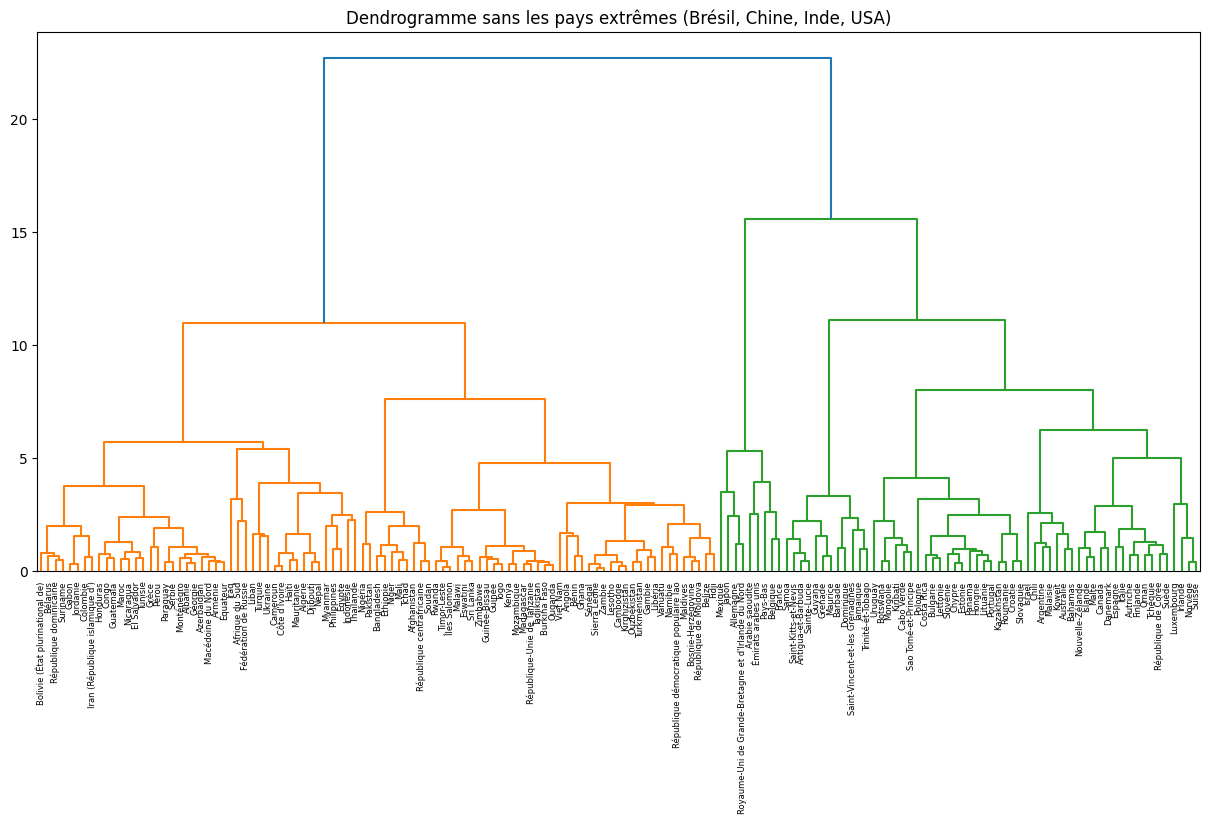

In [93]:
#Dendrogramme
plt.figure(figsize=(15, 7))
dendrogram(Z_propre, labels=col_zones_propre.values, leaf_rotation=90, leaf_font_size=6)
plt.title("Dendrogramme sans les pays extrêmes (Brésil, Chine, Inde, USA)")
plt.show()

Sans les 4 pays extrêmes, l'arbre est mieux équilibré. On choisit 5 clusters, un nombre qui donne des groupes de taille comparable, ni trop nombreux ni trop larges.

In [94]:
clusters_cah_propre = fcluster(Z_propre, t=5, criterion='maxclust')

pd.Series(clusters_cah_propre).value_counts()
print(len(clusters_cah_propre), "pays")

159 pays


### 4.4 Projection des clusters

On recalcule l'ACP sur les 159 pays restants, pour visualiser les 5 clusters CAH.

In [95]:
#Recalcul de l'ACP sur le sous-ensemble sans les 4 pays extrêmes
pca_propre = PCA(n_components=4)
composantes_propre = pca_propre.fit_transform(X_scaled_propre)

In [96]:
print(pca_propre.explained_variance_ratio_)
print(np.cumsum(pca_propre.explained_variance_ratio_))

[0.48575007 0.20050434 0.12046858 0.09919734]
[0.48575007 0.68625441 0.80672299 0.90592032]


Sans les pays extrêmes, les deux premiers axes concentrent 68.6% de l'information pour 159 pays:

- F1 : 48.6%
- F2 : 20.1%

C'est nettement plus qu'avec les 163 pays (60%)

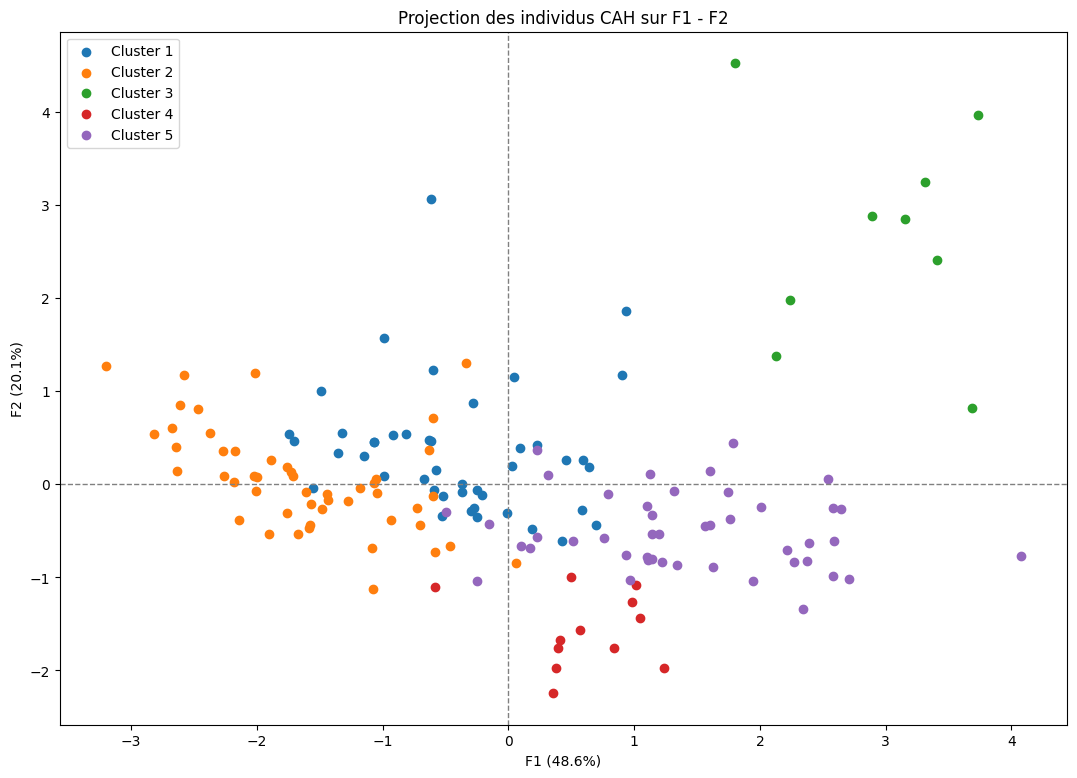

In [97]:
#graphique
fig, ax = plt.subplots(figsize=(13, 9))

for cluster_id in sorted(set(clusters_cah_propre)):
    mask = clusters_cah_propre == cluster_id
    ax.scatter(composantes_propre[mask, 0], composantes_propre[mask, 1], label=f'Cluster {cluster_id}')

ax.axhline(0, color='grey', lw=1, ls='--')
ax.axvline(0, color='grey', lw=1, ls='--')
ax.set_xlabel(f"F1 ({pca_propre.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"F2 ({pca_propre.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Projection des individus CAH sur F1 - F2")
ax.legend()
plt.show()

Ce graphique projette les 159 pays sur le plan F1-F2 de l'ACP, coloré selon leur cluster CAH. On retrouve une répartition cohérente avec le dendrogramme.

### 4.5 Profil des clusters

In [98]:
#Ajout de la colonne aux données réelles
df_clusters = df_final[df_final['Zone'].isin(col_zones_propre.values)].copy()
df_clusters['cluster_cah'] = clusters_cah_propre

# Profil moyen de chaque cluster CAH
profil_clusters_cah = df_clusters.groupby('cluster_cah')[X.columns].mean()
profil_clusters_cah.round(1)

,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique
cluster_cah,,,,,,,,
1,18.1,44.7,62.8,625.3,33111.4,12475.8,64.9,55.4
2,6.3,0.6,25.6,86.6,28813.4,5247.3,36.5,56.4
3,27.2,411.4,696.6,1418.8,59726.4,48620.5,84.1,71.0
4,51.1,0.1,9.7,23.8,620.6,17315.5,40.5,77.4
5,25.2,66.2,60.2,391.2,11916.8,37356.8,74.5,78.1


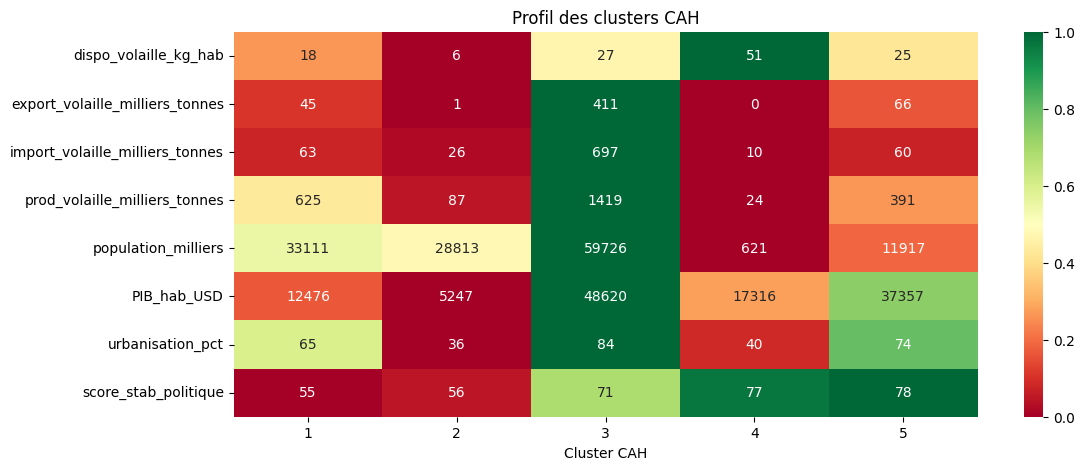

In [99]:
profil_norm_cah = (profil_clusters_cah - profil_clusters_cah.min()) / (profil_clusters_cah.max() - profil_clusters_cah.min())
#Graphique
plt.figure(figsize=(12, 5))
sns.heatmap(profil_norm_cah.T, annot=profil_clusters_cah.T.round(0), fmt='g', cmap='RdYlGn')
plt.title("Profil des clusters CAH")
plt.xlabel("Cluster CAH")
plt.show()

Cette heatmap détaille le profil moyen de chaque cluster CAH sur les 8 variables.
Le vert indique une valeur forte, le rouge une valeur faible, ce qui permet de caractériser rapidement chaque groupe.

- **Cluster 1** : profil intermédiaire, avec un PIB modéré et une stabilité correcte.
- **Cluster 2** : les pays les moins développés, avec le PIB et l'urbanisation les plus faibles.
- **Cluster 3** : forte production et export de volaille, avec la plus grosse population et le PIB le plus élevé. Un profil de géants riches et actifs commercialement.
- **Cluster 4** : petits pays isolés, avec une forte consommation de volaille mais très peu d'échanges commerciaux.
- **Cluster 5** : PIB élevé et meilleure stabilité, avec des échanges commerciaux modérés. Un profil riche et non saturé.

Le **Cluster 5** se distingue comme le profil le plus prometteur pour l'export, il combine un fort pouvoir d'achat et une bonne stabilité, sans être déjà saturé par une forte activité commerciale.

# 5 - K-means

Après la classification ascendante hiérarchique (CAH), nous appliquons une seconde méthode de clustering, le K-means, afin de vérifier la cohérence des regroupements obtenus.

Le K-means fonctionne différemment de la CAH, plutôt que de construire une hiérarchie progressive, il positionne directement k centres, puis assigne chaque pays au centre le plus proche, en ajustant leur position jusqu'à stabilisation.

### 5.1 Méthode du coude et silhouette

Avant de lancer le K-means, on teste plusieurs valeurs de k pour choisir le nombre de clusters le plus pertinent, à l'aide de deux indicateurs : **la méthode du coude** et **le score de silhouette**.

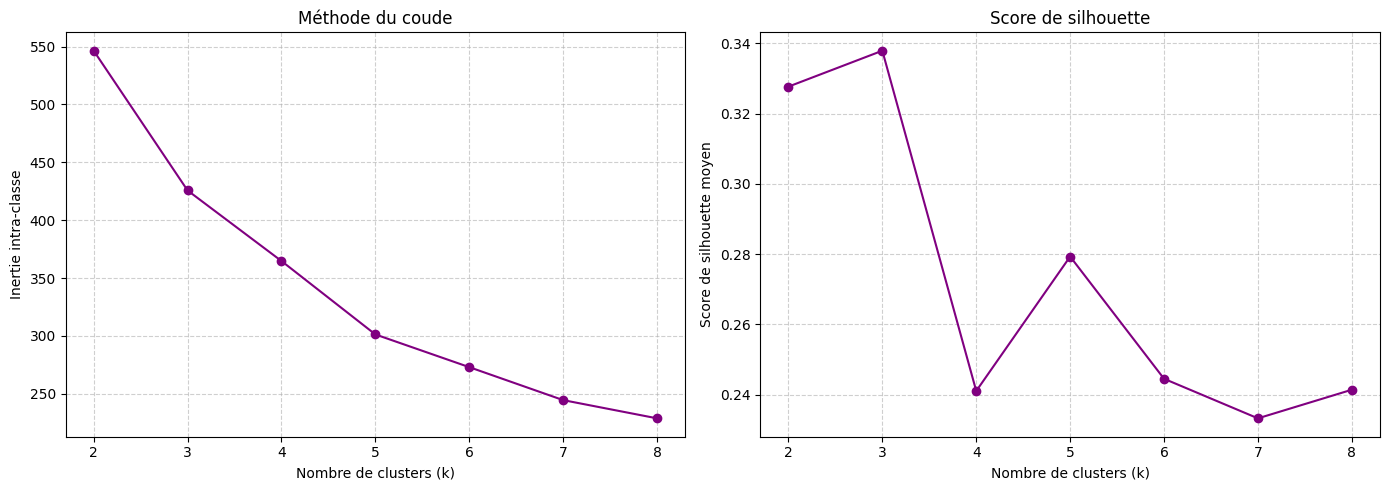

In [100]:
#Graphique
inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled_propre)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled_propre, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_range, inertias, marker='o', color='purple')
ax1.set_title('Méthode du coude')
ax1.set_xlabel('Nombre de clusters (k)')
ax1.set_ylabel('Inertie intra-classe')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(K_range, silhouettes, marker='o', color='purple')
ax2.set_title('Score de silhouette')
ax2.set_xlabel('Nombre de clusters (k)')
ax2.set_ylabel('Score de silhouette moyen')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

- **La méthode du coude** mesure l'inertie (la compacité des clusters) pour différents nombres de k. On cherche le "coude", l'endroit où l'inertie arrête de baisser fortement.

- **Le score de silhouette** mesure à quel point chaque pays est bien classé dans son cluster, comparé aux autres clusters. Plus le score est proche de 1, mieux les pays sont regroupés.

Le score de silhouette est maximal à k=3, mais un découpage aussi large mélangerait des profils de pays très différents. On retient donc k=5, qui reste un bon score et permet de distinguer des profils plus utiles pour cibler des pays précis, en cohérence avec le découpage obtenu par la CAH.

### 5.2 Calcul du K-means


On lance le K-means avec k=5, sur les mêmes 159 pays et les mêmes 8 variables standardisées que la CAH.

In [101]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled_propre)

df_clusters['cluster_kmeans'] = clusters_kmeans
df_clusters['cluster_kmeans'].value_counts()
print(len(df_clusters), "pays")

159 pays


In [102]:
df_clusters['cluster_kmeans'].value_counts()

,count
cluster_kmeans,
0,52
2,49
3,36
1,13
4,9


In [103]:
df_clusters.sort_values('cluster_kmeans')[['Zone', 'cluster_kmeans']]

,Zone,cluster_kmeans
3,Algérie,0
2,Albanie,0
5,Angola,0
9,Arménie,0
12,Azerbaïdjan,0
...,...,...
71,Japon,4
94,Mexique,4
1,Afrique du Sud,4
7,Arabie saoudite,4


Les clusters sont équilibrés, comme avec la CAH, ce qui confirme une bonne cohérence entre les deux méthodes.


### 5.3 Projection des clusters

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


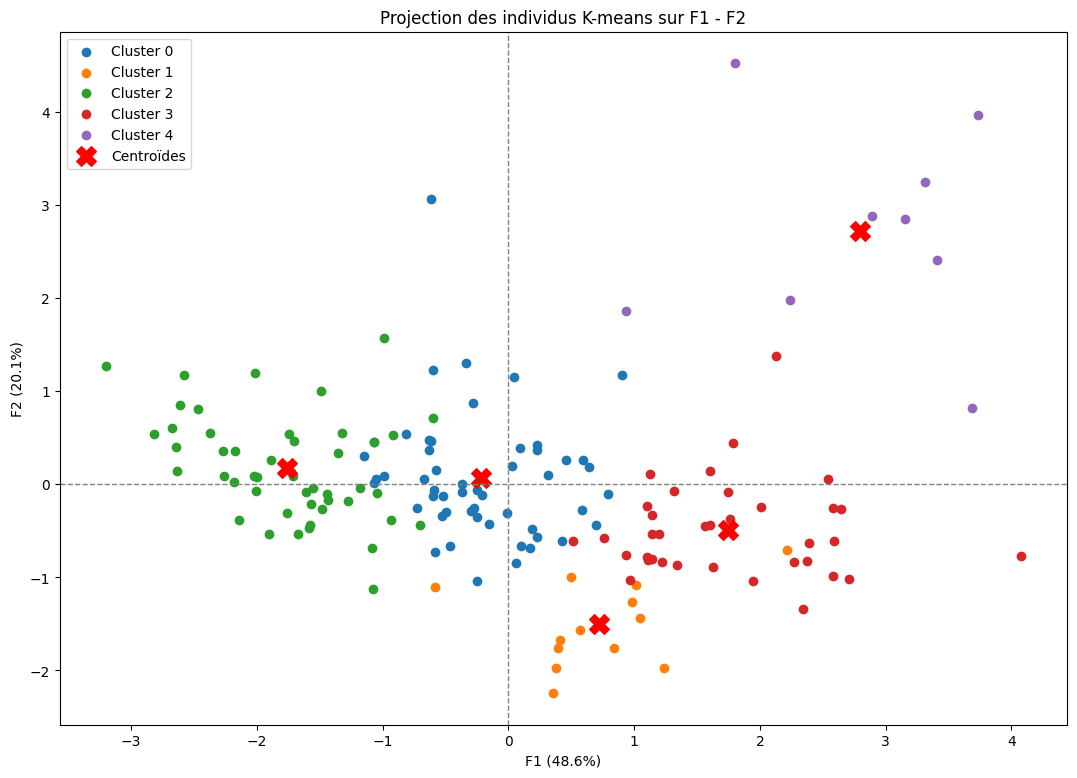

In [104]:
#Graphique
fig, ax = plt.subplots(figsize=(13, 9))

for cluster_id in sorted(set(clusters_kmeans)):
    mask = clusters_kmeans == cluster_id
    ax.scatter(composantes_propre[mask, 0], composantes_propre[mask, 1], label=f'Cluster {cluster_id}')

centroides = kmeans.cluster_centers_
centroides_proj = pca_propre.transform(centroides)
ax.scatter(centroides_proj[:, 0], centroides_proj[:, 1], c='red', marker='X', s=200, label='Centroïdes')

ax.axhline(0, color='grey', lw=1, ls='--')
ax.axvline(0, color='grey', lw=1, ls='--')
ax.set_xlabel(f"F1 ({pca_propre.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"F2 ({pca_propre.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Projection des individus K-means sur F1 - F2")
ax.legend()
plt.show()

Ce graphique projette les 159 pays sur le plan F1-F2 de l'ACP, coloré selon leur cluster K-means, avec les centroïdes (croix rouges) marquant le centre de chaque groupe.

### 5.4 Profil des clusters

In [105]:
#On ajoute la colonne cluster aux données NON standardisées
df_clusters['cluster_kmeans'] = clusters_kmeans

#Profil moyen de chaque cluster
profil_clusters = df_clusters.groupby('cluster_kmeans')[X.columns].mean()
profil_clusters.round(1)

,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique
cluster_kmeans,,,,,,,,
0,17.6,24.2,55.8,358.7,17038.4,12945.0,65.2,61.8
1,52.4,0.3,8.9,70.3,1207.0,19010.6,44.4,75.9
2,5.6,16.5,22.1,248.4,40427.5,5327.0,35.7,53.1
3,26.6,97.1,71.3,463.9,13451.0,43058.6,77.3,79.3
4,29.8,345.6,716.1,1552.6,64792.0,44563.0,81.5,69.6


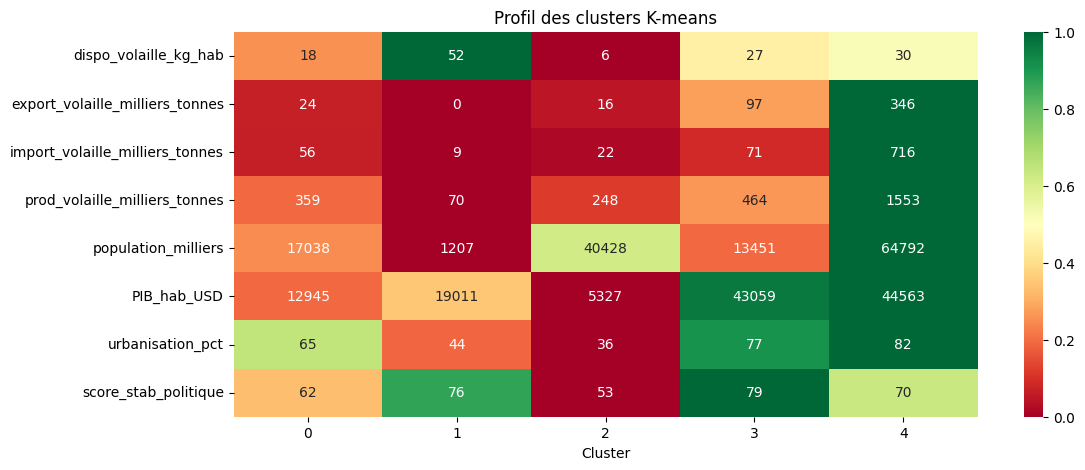

In [106]:
profil_norm = (profil_clusters - profil_clusters.min()) / (profil_clusters.max() - profil_clusters.min())

plt.figure(figsize=(12, 5))
sns.heatmap(profil_norm.T, annot=profil_clusters.T.round(0), fmt='g', cmap='RdYlGn')
plt.title("Profil des clusters K-means")
plt.xlabel("Cluster")
plt.show()

Cette heatmap détaille le profil moyen de chaque cluster K-means sur les 8 variables. Le vert indique une valeur forte, le rouge une valeur faible, ce qui permet de caractériser rapidement chaque groupe.

- **Cluster 0** : profil intermédiaire, avec un PIB modéré et une stabilité correcte.
- **Cluster 1** : petits pays isolés, avec une forte consommation de volaille mais très peu d'échanges commerciaux.
- **Cluster 2** : les pays les moins développés, avec le PIB et l'urbanisation les plus faibles.
- **Cluster 3** : PIB élevé et meilleure stabilité, avec des échanges commerciaux modérés. Un profil riche et non saturé.
- **Cluster 4** : forte production et export de volaille, avec la plus grosse population et le PIB le plus élevé. Un profil de géants riches et actifs commercialement.

Le **Cluster 3** se distingue comme le profil le plus prometteur pour l'export, il combine un fort pouvoir d'achat et une bonne stabilité, sans être déjà saturé par une forte activité commerciale.

# 6 - Comparaison CAH vs K-means

In [107]:
df_clusters[df_clusters['Zone'] == 'France']

,Zone,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique,distance_fr_km,cluster_cah,cluster_kmeans
47,France,22.9,501.0,506.0,1750.0,64842.509,44469.145886,78.64678,69.822683,1.780359,3,4


In [108]:
#tableau des deux résultats
comparaison = pd.DataFrame({'Zone': col_zones_propre.values, 'cluster_cah': clusters_cah_propre, 'cluster_kmeans': clusters_kmeans})

#Tableau croisé CAH K-means
tableau_croise = pd.crosstab(comparaison['cluster_cah'], comparaison['cluster_kmeans'])
tableau_croise

cluster_kmeans,0,1,2,3,4
cluster_cah,,,,,
1,34,0,9,0,1
2,9,0,40,0,0
3,0,0,0,1,8
4,0,12,0,0,0
5,9,1,0,35,0


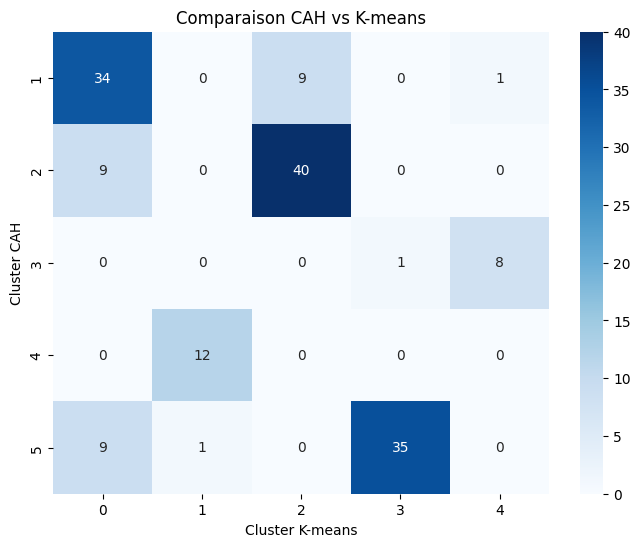

In [109]:
plt.figure(figsize=(8, 6))
sns.heatmap(tableau_croise, annot=True, fmt='d', cmap='Blues')
plt.title("Comparaison CAH vs K-means")
plt.xlabel("Cluster K-means")
plt.ylabel("Cluster CAH")
plt.show()

Cette heatmap croise les clusters obtenus par la CAH et par le K-means. Chaque case indique combien de pays partagent la même combinaison des deux.

On observe une forte concordance entre les deux méthodes, chaque cluster CAH correspondant très majoritairement à un seul cluster K-means.

Le **cluster 1** K-means correspond exactement au **cluster 4** CAH.

Le **cluster 3** K-means, qui deviendra le marché cible retenu, correspond en grande partie au **cluster 5** CAH.


**Compte tenu de cette cohérence, on retient la segmentation K-means pour la suite de l'analyse. Contrairement à la CAH, qui construit une hiérarchie de regroupements, le K-means donne directement des groupes fixes et indépendants, plus simples à exploiter pour calculer des profils et des scores par pays.**

# 7 - Choix du marché cible

On approfondit maintenant l'analyse du **Cluster 3** de K-means, retenu comme cible prioritaire pour l'export, afin d'identifier les pays les plus prometteurs à l'intérieur de ce groupe.

### 7.1 Détail des pays du Cluster 3

In [110]:
df_clusters[df_clusters['cluster_kmeans'] == 3][['Zone', 'PIB_hab_USD', 'score_stab_politique', 'distance_fr_km']].sort_values('distance_fr_km')

,Zone,PIB_hab_USD,score_stab_politique,distance_fr_km
16,Belgique,50256.063177,72.125081,261.979827
83,Luxembourg,114985.842236,87.614367,286.348823
137,Suisse,69317.599392,85.780049,438.994441
66,Irlande,80409.454840,81.981889,778.868838
143,Tchéquie,39346.030564,83.317537,887.583911
134,Slovénie,36180.038455,82.045215,967.661713
38,Danemark,55271.597600,81.522409,1028.551393
11,Autriche,53869.832118,81.723836,1036.208483
42,Espagne,39825.249812,70.687849,1053.922593
133,Slovaquie,30245.782587,80.486378,1092.143148


### 7.2 Calcul du scoring

On calcule un score combinant plusieurs variables, pour classer les pays  selon leur potentiel de marché.

Le score augmente avec la consommation, l'import, le pouvoir d'achat, l'urbanisation, la stabilité et la population et diminue avec l'export et la production.

In [111]:
variables_positif = ['dispo_volaille_kg_hab', 'import_volaille_milliers_tonnes', 'PIB_hab_USD', 'urbanisation_pct', 'score_stab_politique', 'population_milliers']
variables_negatif = ['export_volaille_milliers_tonnes', 'prod_volaille_milliers_tonnes']

score = X_scaled_propre[variables_positif].sum(axis=1) - X_scaled_propre[variables_negatif].sum(axis=1)
df_clusters['score'] = score.values

In [112]:
cluster_3 = df_clusters[df_clusters['cluster_kmeans'] == 3].copy()
cluster_3.sort_values('score', ascending=False)

,Zone,dispo_volaille_kg_hab,export_volaille_milliers_tonnes,import_volaille_milliers_tonnes,prod_volaille_milliers_tonnes,population_milliers,PIB_hab_USD,urbanisation_pct,score_stab_politique,distance_fr_km,cluster_cah,cluster_kmeans,score
83,Luxembourg,18.33,1.0,11.0,0.0,591.910,114985.842236,92.096377,87.614367,286.348823,5,3,7.948168
77,Koweït,46.25,4.0,137.0,56.0,4056.099,46565.549950,100.000000,65.926074,4411.066181,5,3,5.682478
67,Islande,29.95,0.0,2.0,10.0,334.393,56385.043000,93.771898,87.252499,2238.669855,5,3,5.602910
29,Canada,39.02,163.0,182.0,1417.0,36732.095,48317.500303,81.401895,83.304206,5665.594069,5,3,5.236814
38,Danemark,28.98,139.0,133.0,173.0,5732.274,55271.597600,88.016194,81.522409,1028.551393,5,3,5.219421
66,Irlande,25.82,93.0,99.0,110.0,4753.279,80409.454840,62.903520,81.981889,778.868838,5,3,5.117758
10,Australie,47.65,42.0,16.0,1269.0,24584.620,48564.828659,87.128093,79.271813,16915.714773,5,3,5.095866
104,Nouvelle-Zélande,34.79,23.0,1.0,223.0,4702.034,42205.907171,84.170103,91.388422,18980.732071,5,3,4.890752
137,Suisse,15.72,4.0,51.0,91.0,8455.804,69317.599392,77.912627,85.780049,438.994441,5,3,4.814080
90,Malte,27.17,0.0,9.0,4.0,437.933,45763.696810,94.569181,84.390828,1749.627236,5,3,4.746614


In [113]:
#Standardisation de la distance, utilisée uniquement ici pour le score final
distance_scaled = (df_clusters['distance_fr_km'] - df_clusters['distance_fr_km'].mean()) / df_clusters['distance_fr_km'].std()
score_avec_distance = df_clusters['score'] - distance_scaled
df_clusters['score_avec_distance'] = score_avec_distance

In [114]:
#On recrée cluster_3 pour avoir les 2 scores dedans
cluster_3 = df_clusters[df_clusters['cluster_kmeans'] == 3].copy()
cluster_3[['Zone', 'score', 'score_avec_distance', 'distance_fr_km', 'population_milliers']].sort_values('score_avec_distance', ascending=False).head(10)

,Zone,score,score_avec_distance,distance_fr_km,population_milliers
83,Luxembourg,7.948168,9.369386,286.348823,591.910
67,Islande,5.602910,6.517798,2238.669855,334.393
38,Danemark,5.219421,6.448150,1028.551393,5732.274
66,Irlande,5.117758,6.411242,778.868838,4753.279
137,Suisse,4.814080,6.195710,438.994441,8455.804
77,Koweït,5.682478,6.033960,4411.066181,4056.099
103,Norvège,4.714119,5.861014,1344.089683,5296.326
90,Malte,4.746614,5.788334,1749.627236,437.933
29,Canada,5.236814,5.262936,5665.594069,36732.095
139,Suède,4.138180,5.232675,1546.138715,9904.896


### 7.3 Conclusion

Le Cluster 3 (36 pays) est retenu comme cible prioritaire pour les raisons suivantes :

- **Pouvoir d'achat élevé** : PIB par habitant comparable aux pays les plus riches de l'analyse.
- **Meilleure stabilité politique** de tous les clusters, un facteur clé de sécurité pour l'investissement.
- **Marché non saturé** : des volumes d'export/import de volaille nettement plus modérés que le Cluster 4, suggérant une concurrence internationale moins installée.
- **Proximité géographique favorable** : la distance moyenne la plus courte de tous les clusters.

En combinant le score de profil (richesse, stabilité, marché ouvert) et la distance à la France, le Luxembourg ressort comme le candidat le plus solide, suivi de l'Islande, du Danemark, de l'Irlande et de la Suisse.

Ce classement met en avant des marchés premium à forte valeur ajoutée, mais souvent de petite taille.